# 3.6 Ensembles

Bagging, random forests (incl. variable importance), and boosting/AdaBoost
-- all built from the same decision-tree building block as 3.5, on the
identical churn target/features/split.

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

Every classification notebook predicts the **same target, from the same
features, on the same train/test split** -- so the confusion matrix/ROC/AUC
numbers below are directly comparable to the other technique notebooks in
this folder.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.model_selection import train_test_split
from plotting import plot_confusion, plot_roc, plot_lift

features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
X = df[features]
y = df["churned"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("train:", Xtr.shape, " test:", Xte.shape, " churn rate (train/test):", round(ytr.mean(),3), round(yte.mean(),3))

train: (210, 7)  test: (90, 7)  churn rate (train/test): 0.338 0.344


## Bagging: bootstrap aggregation

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score

single_tree = DecisionTreeClassifier(max_depth=4, random_state=0).fit(Xtr, ytr)
bagged = BaggingClassifier(DecisionTreeClassifier(max_depth=4), n_estimators=200, oob_score=True, random_state=0).fit(Xtr, ytr)

print("Single tree test AUC:", round(roc_auc_score(yte, single_tree.predict_proba(Xte)[:, 1]), 3))
print("Bagged trees test AUC:", round(roc_auc_score(yte, bagged.predict_proba(Xte)[:, 1]), 3))
print("Bagging OOB score (no test set needed!):", round(bagged.oob_score_, 3))

Single tree test AUC: 0.61
Bagged trees test AUC: 0.68
Bagging OOB score (no test set needed!): 0.662


Bagging fits many trees, each on its own bootstrap resample (Foundations
1.2's bootstrap, reused directly), and averages their predictions --
variance goes down because uncorrelated errors partly cancel out. The
`oob_score_` above reuses each tree's own left-out ("out-of-bag") rows as a
free validation set, no separate test split needed.

## Random forests: extending bagging, and variable importance

Random forest test AUC: 0.679
Random forest OOB score: 0.652


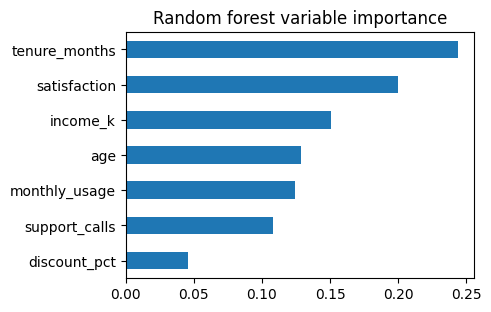

In [4]:
rf = RandomForestClassifier(n_estimators=300, max_depth=6, oob_score=True, random_state=0).fit(Xtr, ytr)
print("Random forest test AUC:", round(roc_auc_score(yte, rf.predict_proba(Xte)[:, 1]), 3))
print("Random forest OOB score:", round(rf.oob_score_, 3))

importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(4.5, 3.2))
importances.plot.barh(ax=ax); ax.invert_yaxis(); ax.set_title("Random forest variable importance")
plt.show()

Random forests add one extra trick on top of bagging: each split only
considers a **random subset** of features, decorrelating the trees further
(two trees can't both split on the single strongest predictor every time).

## Boosting and AdaBoost

In [5]:
ada = AdaBoostClassifier(n_estimators=200, random_state=0).fit(Xtr, ytr)
gb = GradientBoostingClassifier(n_estimators=200, max_depth=2, random_state=0).fit(Xtr, ytr)
print("AdaBoost test AUC          :", round(roc_auc_score(yte, ada.predict_proba(Xte)[:, 1]), 3))
print("Gradient boosting test AUC :", round(roc_auc_score(yte, gb.predict_proba(Xte)[:, 1]), 3))

AdaBoost test AUC          : 0.661
Gradient boosting test AUC : 0.677


Boosting fits trees **sequentially**, each one focused on the previous
ensemble's mistakes (AdaBoost reweights misclassified rows; gradient
boosting fits the residual/gradient directly) -- a different way of
combining weak trees than bagging's "many independent votes".

In [6]:
clf = rf

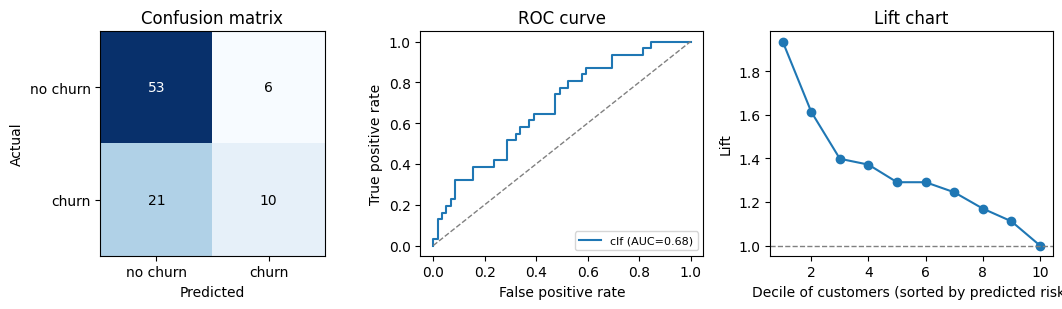

AUC: 0.679


In [7]:
y_pred = clf.predict(Xte)
y_score = clf.predict_proba(Xte)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
plot_confusion(yte, y_pred, ax=axes[0])
auc_val = plot_roc(yte, y_score, ax=axes[1], label="clf")
plot_lift(yte, y_score, ax=axes[2])
plt.tight_layout(); plt.show()
print("AUC:", round(auc_val, 3))

**Wrap-up**: bagging/random forests reduce variance by averaging
independent trees; boosting reduces bias by building trees that
deliberately correct earlier mistakes. Compare the AUC numbers above
against the single decision tree from 3.5 on the identical split.